In [1]:
%pip -q install requests pandas pyarrow duckdb psycopg2-binary sqlalchemy

# PCA

In [38]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Upload wallet_features.csv to Colab first
W = pd.read_csv("wallet_features.csv")

# Apply the course demo's high-activity wallet filter
H = W[
    (W["unique_markets"] < 500) &
    (W["trade_count"] < 2000)
].copy()

print("Wallets analyzed:", len(H))
print("Known positives:", H["confirmed"].sum())


Wallets analyzed: 55668
Known positives: 18


In [39]:

features = [
    "position_anomaly_ratio",
    "market_notional_ratio",
    "avg_buy_price",
    "concentration",
    "wallet_age_days",
    "unique_markets"
]

# Log-transform skewed nonnegative features
X = np.log1p(H[features].clip(lower=0))

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=3, random_state=42)
X_pca = pca.fit_transform(X_scaled)

# Variance-adjusted distance in PCA space
H["pca_distance"] = np.sqrt(
    np.sum(
        (X_pca / np.sqrt(pca.explained_variance_)) ** 2,
        axis=1
    )
)

H = H.sort_values(
    "pca_distance",
    ascending=False
).reset_index(drop=True)

H["pca_rank"] = np.arange(1, len(H) + 1)

print(
    "Explained variance:",
    f"{pca.explained_variance_ratio_.sum() * 100:.2f}%"
)


Explained variance: 76.59%


In [40]:

k = int(np.ceil(0.01 * len(H)))

H["flagged"] = H["pca_rank"] <= k

flagged_wallets = H[H["flagged"]].copy()

print("Wallets flagged:", len(flagged_wallets))
print(
    "Confirmed wallets found:",
    int(flagged_wallets["confirmed"].sum())
)
print(
    "Total known positives evaluated:",
    int(H["confirmed"].sum())
)

# Show the highest-ranked wallets
display(
    flagged_wallets[
        [
            "wallet",
            "pca_rank",
            "pca_distance",
            "trade_count",
            "total_notional",
            "unique_markets",
            "confirmed"
        ]
    ].head(20)
)


Wallets flagged: 557
Confirmed wallets found: 3
Total known positives evaluated: 18


,wallet,pca_rank,pca_distance,trade_count,total_notional,unique_markets,confirmed
0,w_1a6b6adb7f,1,32.507756,1308,1.506350e+06,69,False
1,w_0ad921959f,2,31.260063,240,3.363520e+05,43,False
2,w_d10eb42459,3,30.468418,30,5.453132e+01,22,False
3,w_8c69cfa6f4,4,30.460786,334,1.471645e+05,52,False
4,w_5edb5b7b04,5,29.725597,809,2.004197e+05,38,False
5,w_a00a1221f3,6,28.810296,309,2.586704e+05,55,False
6,w_2a6f56b83f,7,28.492563,929,6.631332e+04,135,False
7,w_9fc38fe70e,8,28.323942,121,1.870333e+04,17,False
8,w_ab7b2a7ce4,9,25.715510,5,1.758469e+03,4,False
9,w_47659a4732,10,25.675169,1553,1.860667e+06,131,False


In [41]:

confirmed_found = flagged_wallets[
    flagged_wallets["confirmed"]
]

display(
    confirmed_found[
        [
            "wallet",
            "pca_rank",
            "pca_distance",
            "total_notional",
            "position_anomaly_ratio",
            "market_notional_ratio"
        ]
    ]
)


,wallet,pca_rank,pca_distance,total_notional,position_anomaly_ratio,market_notional_ratio
98,w_2a43266bd8,99,10.711141,675486.923909,4.062995,0.260756
215,w_bc876cca82,216,6.684042,359435.594701,0.606562,0.150682
477,w_bae5b984cf,478,4.134215,297220.768101,1.575241,0.093145


In [42]:

H.to_csv(
    "pca_all_wallet_rankings.csv",
    index=False
)

flagged_wallets.to_csv(
    "pca_flagged_wallets.csv",
    index=False
)

print("Saved wallet rankings and flagged-wallet list.")


Saved wallet rankings and flagged-wallet list.


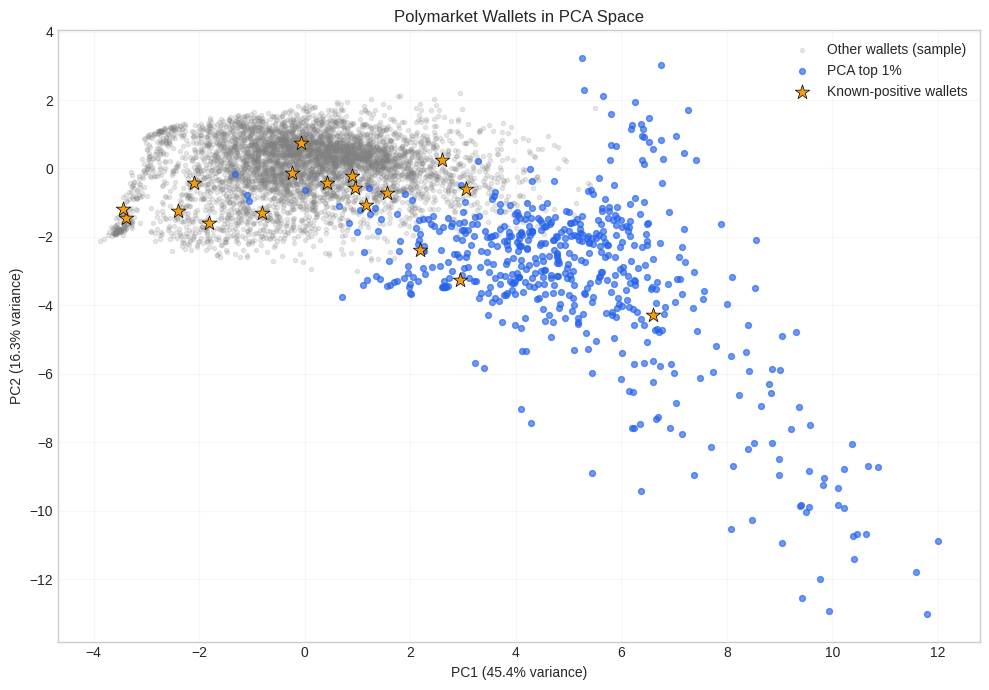

In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# H was sorted after PCA was fitted, so preserve the
# original PCA coordinates by matching them to wallet IDs.
wallet_coords = pd.DataFrame({
    "wallet": W.loc[
        (W["unique_markets"] < 500) &
        (W["trade_count"] < 2000),
        "wallet"
    ].values,
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1]
})

plot_df = H.merge(
    wallet_coords,
    on="wallet",
    how="left",
    validate="one_to_one"
)

# Plot a reproducible sample of unflagged wallets
normal = plot_df[~plot_df["flagged"]]
normal_sample = normal.sample(
    n=min(5000, len(normal)),
    random_state=42
)

flagged = plot_df[plot_df["flagged"]]
confirmed = plot_df[plot_df["confirmed"].astype(bool)]

plt.figure(figsize=(10, 7))

plt.scatter(
    normal_sample["PC1"], normal_sample["PC2"],
    s=9, alpha=0.18, color="gray",
    label="Other wallets (sample)"
)

plt.scatter(
    flagged["PC1"], flagged["PC2"],
    s=18, alpha=0.65, color="#2563eb",
    label="PCA top 1%"
)

plt.scatter(
    confirmed["PC1"], confirmed["PC2"],
    s=120, marker="*", color="#f59e0b",
    edgecolors="black", linewidths=0.5,
    label="Known-positive wallets",
    zorder=5
)

plt.xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)"
)
plt.ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)"
)

plt.title("Polymarket Wallets in PCA Space")
plt.legend()
plt.grid(alpha=0.15)
plt.tight_layout()

plt.savefig(
    "pca_wallet_scatter.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Each point represents one wallet. Blue points are wallets ranked in the top 1% by PCA distance,
# while orange stars represent known-positive cases.
# The plot shows only two components, although the ranking uses three.

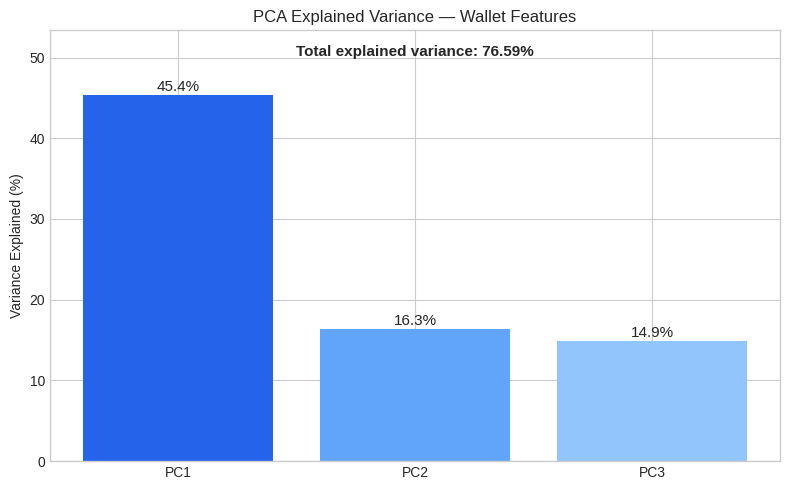

In [44]:
variance = pca.explained_variance_ratio_ * 100

plt.figure(figsize=(8, 5))

bars = plt.bar(
    ["PC1", "PC2", "PC3"],
    variance,
    color=["#2563eb", "#60a5fa", "#93c5fd"]
)

for bar, value in zip(bars, variance):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.5,
        f"{value:.1f}%",
        ha="center",
        fontsize=11
    )

plt.ylabel("Variance Explained (%)")
plt.title("PCA Explained Variance — Wallet Features")
plt.ylim(0, max(variance) + 8)

plt.text(
    0.5, 0.94,
    f"Total explained variance: {variance.sum():.2f}%",
    transform=plt.gca().transAxes,
    ha="center",
    fontsize=11,
    fontweight="bold"
)

plt.tight_layout()
plt.savefig(
    "pca_explained_variance.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


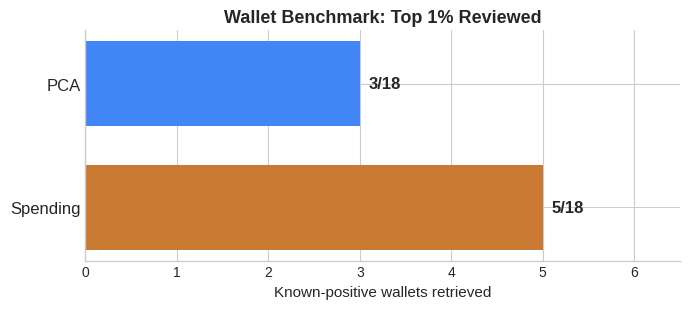

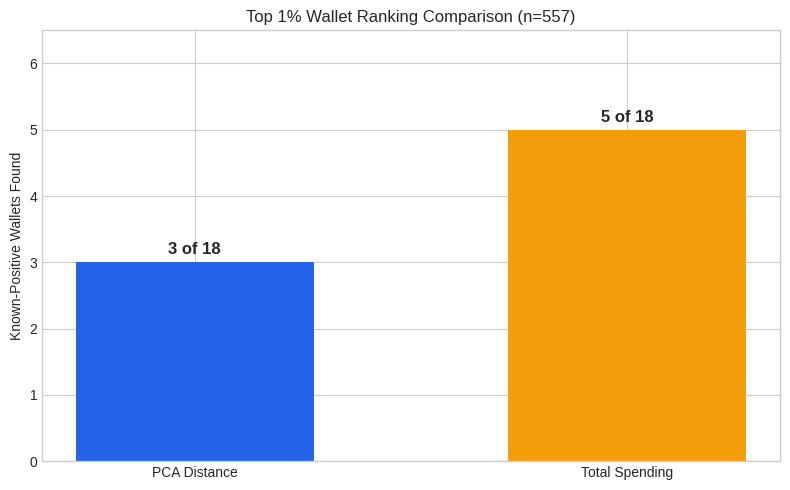

PCA found: 3/18
Spending found: 5/18


In [47]:
k = int(np.ceil(0.01 * len(H)))

# PCA top 1%
pca_top = H.nsmallest(k, "pca_rank")

import matplotlib.pyplot as plt
import numpy as np

# Use your existing PCA results
k = int(np.ceil(0.01 * len(H)))

pca_found = int(
    H.nsmallest(k, "pca_rank")["confirmed"].sum()
)
spending_found = int(
    H.nlargest(k, "total_notional")["confirmed"].sum()
)
total_confirmed = int(H["confirmed"].sum())

labels = ["PCA", "Spending"]
values = [pca_found, spending_found]

# Positions closer together
y_pos = [0, 0.55]

fig, ax = plt.subplots(figsize=(7, 3.2))

bars = ax.barh(
    y_pos,
    values,
    height=0.38,
    color=["#4285F4", "#C97932"]
)

ax.set_yticks(y_pos)
ax.set_yticklabels(labels, fontsize=12)
ax.invert_yaxis()

# Values at the end of each bar
for bar, value in zip(bars, values):
    ax.text(
        value + 0.1,
        bar.get_y() + bar.get_height() / 2,
        f"{value}/{total_confirmed}",
        va="center",
        fontsize=12,
        fontweight="bold"
    )

ax.set_xlim(0, 6.5)
ax.set_xlabel("Known-positive wallets retrieved", fontsize=11)
ax.set_title(
    "Wallet Benchmark: Top 1% Reviewed",
    fontsize=13,
    fontweight="bold"
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig(
    "pca_vs_spending_compact.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Spending baseline: rank by total traded volume
spending_top = H.nlargest(k, "total_notional")
spending_found = int(spending_top["confirmed"].sum())

total_confirmed = int(H["confirmed"].sum())

methods = ["PCA Distance", "Total Spending"]
counts = [pca_found, spending_found]

plt.figure(figsize=(8, 5))

bars = plt.bar(
    methods,
    counts,
    color=["#2563eb", "#f59e0b"],
    width=0.55
)

for bar, count in zip(bars, counts):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        count + 0.12,
        f"{count} of {total_confirmed}",
        ha="center",
        fontsize=12,
        fontweight="bold"
    )

plt.ylabel("Known-Positive Wallets Found")
plt.title(f"Top 1% Wallet Ranking Comparison (n={k:,})")
plt.ylim(0, max(counts) + 1.5)
plt.tight_layout()

plt.savefig(
    "pca_vs_spending.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print(f"PCA found: {pca_found}/{total_confirmed}")
print(f"Spending found: {spending_found}/{total_confirmed}")


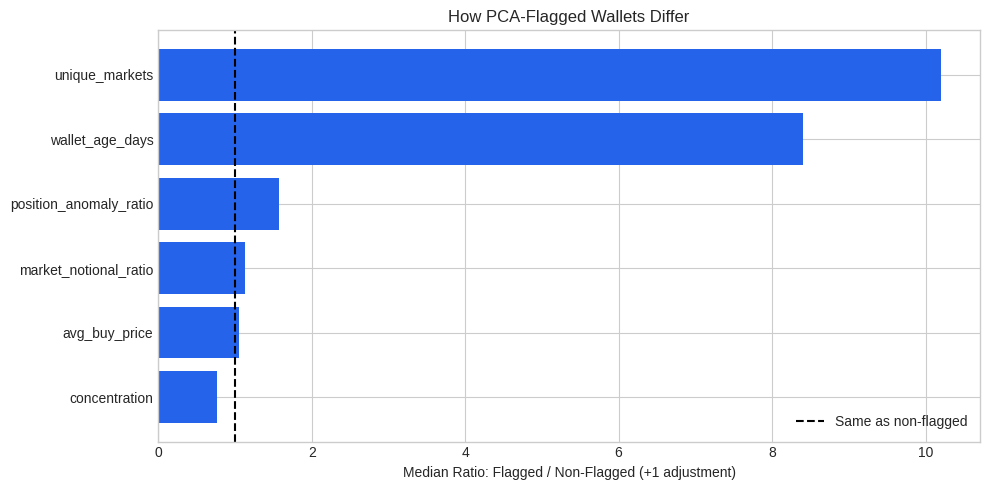

In [46]:

# Median feature values, expressed relative to the
# non-flagged group's median for easier comparison.
medians = H.groupby("flagged")[features].median()

relative = (
    (medians.loc[True] + 1)
    / (medians.loc[False] + 1)
)

relative = relative.sort_values()

plt.figure(figsize=(10, 5))

plt.barh(
    relative.index,
    relative.values,
    color="#2563eb"
)

plt.axvline(
    1,
    color="black",
    linestyle="--",
    label="Same as non-flagged"
)

plt.xlabel("Median Ratio: Flagged / Non-Flagged (+1 adjustment)")
plt.title("How PCA-Flagged Wallets Differ")
plt.legend()
plt.tight_layout()

plt.savefig(
    "pca_wallet_feature_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
